In [26]:
!pip install pandas matplotlib seaborn numpy statsmodels xlrd

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import os


In [13]:
import pandas as pd

df = pd.read_csv("Kroegrekening.csv", sep=";", decimal=",")
print(df.head())

  Gedownload op       2026-10-13 15:35:36  \
0       Relatie  J.R.H. (Jannes) Holdinga   
1           NaN                       NaN   
2           Nr.                     Datum   
3             1                27-08-2022   
4             2                29-08-2022   

                               Unnamed: 2 Unnamed: 3 Unnamed: 4  \
0                                     NaN        NaN        NaN   
1                                     NaN        NaN        NaN   
2                            Omschrijving      Debet     Credit   
3         Wijn installatiediner jaar 2022     € 3,16        NaN   
4  Omslag hospiteerborrel 21/22 29-8-2022    € 28,78        NaN   

          Unnamed: 5 Unnamed: 6  
0                NaN        NaN  
1                NaN        NaN  
2  Grootboekrekening    Periode  
3              11000  2021 - 11  
4              11000  2021 - 11  


In [15]:
with open("Kroegrekening.csv", encoding="utf-8-sig") as f:
    for i, regel in enumerate(f):
        print(i, regel.rstrip())
        if i >= 10:
            break

0 Gedownload op;2026-10-13 15:35:36;;;;;
1 Relatie;J.R.H. (Jannes) Holdinga;;;;;
2 ;;;;;;
3 Nr.;Datum;Omschrijving;Debet;Credit;Grootboekrekening;Periode
4 1;27-08-2022;Wijn installatiediner jaar 2022;€ 3,16;;11000;2021 - 11
5 2;29-08-2022;Omslag hospiteerborrel 21/22 29-8-2022;€ 28,78;;11000;2021 - 11
6 3;30-08-2022;Nieuwe kroegpas;€ 7,50;;11000;2021 - 11
7 4;22-09-2022;J.R.H. Holdinga JRH (Jannes) Holdinga 2022094;;€ 39,44;11000;2021 - 12
8 5;30-09-2022;Glaswerk & plastic societeit augustus & september;€ 3,91;;11000;2021 - 12
9 6;30-09-2022;Verdeling jaarbier en daghap september;€ 319,36;;11000;2021 - 12
10 7;12-10-2022;Omslag Crusa merchandise;€ 53,23;;11000;2022 - 1


In [21]:
import pandas as pd
import numpy as np

df = pd.read_csv("Kroegrekening.csv", sep=";", skiprows=3,
                 encoding="utf-8-sig", dtype=str)
df.columns = df.columns.str.strip()

def naar_getal(serie):
    return pd.to_numeric(
        serie.fillna("")
             .str.replace("€", "", regex=False)
             .str.replace(".", "", regex=False)   # duizendtallen-punt weg
             .str.replace(",", ".", regex=False)  # decimaal-komma naar punt
             .str.strip(),
        errors="coerce")

df["Debet"] = naar_getal(df["Debet"])
df["Datum"] = pd.to_datetime(df["Datum"], format="%d-%m-%Y", errors="coerce")

# Alleen uitgaven: regels met een Debet-bedrag
uitgaven = df.dropna(subset=["Datum", "Debet"])
uitgaven = uitgaven[uitgaven["Debet"] > 0]

per_jaar = uitgaven.groupby(uitgaven["Datum"].dt.year)["Debet"].sum()
print(per_jaar)

# Lineaire trend en voorspelling
jaren = per_jaar.index.values.astype(float)
totalen = per_jaar.values
helling, intercept = np.polyfit(jaren, totalen, 1)
volgend_jaar = jaren.max() + 1
print(f"Voorspelling {int(volgend_jaar)}: € {helling * volgend_jaar + intercept:.2f}")
print(f"Gemiddelde verandering per jaar: € {helling:.2f}")

Datum
2022    1648.59
2023    3980.19
2024    2473.56
2025    2386.76
2026     635.37
Name: Debet, dtype: float64
Voorspelling 2027: € 1138.93
Gemiddelde verandering per jaar: € -361.99


In [20]:
df = pd.read_csv("Kroegrekening.csv", sep=";", decimal=",",
                 encoding="utf-8-sig", skiprows=kop)  # kop uit het vorige script
print(list(df.columns))

['Nr.', 'Datum', 'Omschrijving', 'Debet', 'Credit', 'Grootboekrekening', 'Periode']


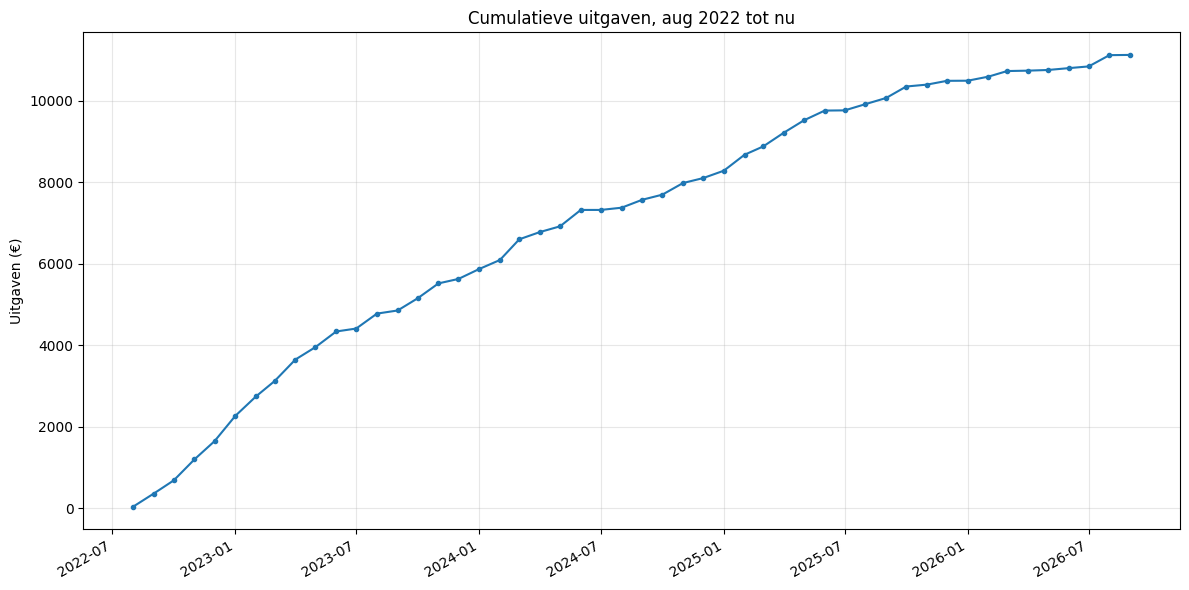

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Kroegrekening.csv", sep=";", skiprows=3,
                 encoding="utf-8-sig", dtype=str)
df.columns = df.columns.str.strip()

def naar_getal(serie):
    return pd.to_numeric(
        serie.fillna("")
             .str.replace("€", "", regex=False)
             .str.replace(".", "", regex=False)
             .str.replace(",", ".", regex=False)
             .str.strip(),
        errors="coerce")

df["Debet"] = naar_getal(df["Debet"])
df["Datum"] = pd.to_datetime(df["Datum"], format="%d-%m-%Y", errors="coerce")

uitgaven = df.dropna(subset=["Datum", "Debet"])
uitgaven = uitgaven[uitgaven["Debet"] > 0].copy()

# Totaal per maand, als datum op de 1e van de maand
uitgaven["Maand"] = uitgaven["Datum"].dt.to_period("M").dt.to_timestamp()
per_maand = uitgaven.groupby("Maand")["Debet"].sum()

# Elke maand tussen de eerste en laatste maand, zonder gaten
alle_maanden = pd.date_range(per_maand.index.min(), per_maand.index.max(), freq="MS")
per_maand = per_maand.reindex(alle_maanden, fill_value=0)
cumulatief = per_maand.cumsum()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(cumulatief.index, cumulatief.values, marker="o", markersize=3)
ax.set_title("Cumulatieve uitgaven, aug 2022 tot nu")
ax.set_ylabel("Uitgaven (€)")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

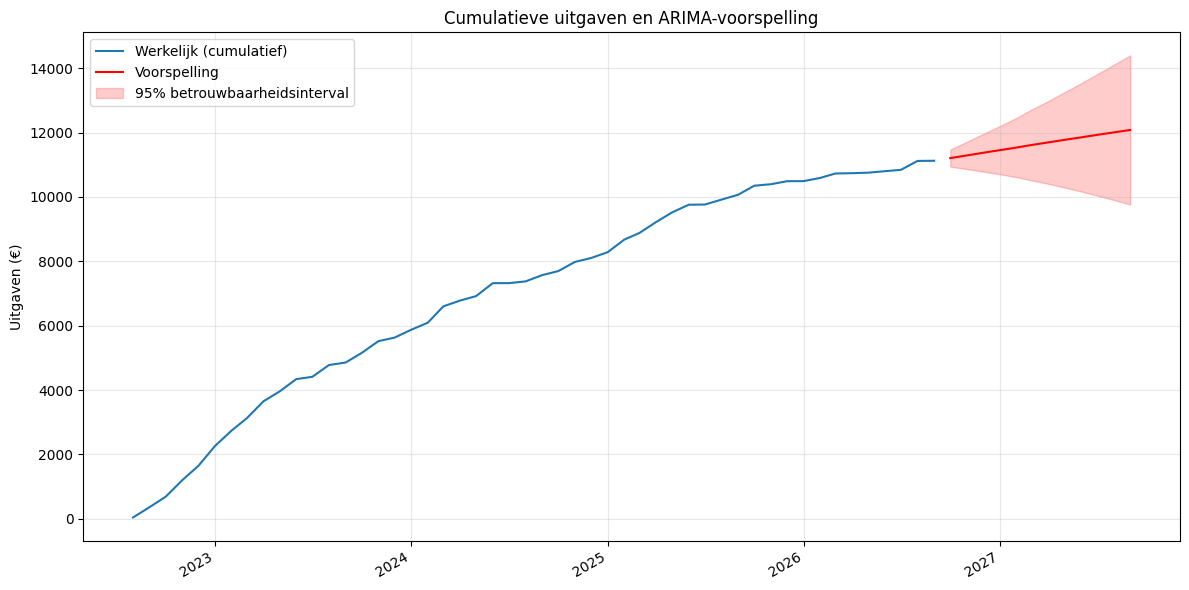

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

df = pd.read_csv("Kroegrekening.csv", sep=";", skiprows=3,
                 encoding="utf-8-sig", dtype=str)
df.columns = df.columns.str.strip()

def naar_getal(serie):
    return pd.to_numeric(
        serie.fillna("")
             .str.replace("€", "", regex=False)
             .str.replace(".", "", regex=False)
             .str.replace(",", ".", regex=False)
             .str.strip(),
        errors="coerce")

df["Debet"] = naar_getal(df["Debet"])
df["Datum"] = pd.to_datetime(df["Datum"], format="%d-%m-%Y", errors="coerce")

uitgaven = df.dropna(subset=["Datum", "Debet"])
uitgaven = uitgaven[uitgaven["Debet"] > 0].copy()
uitgaven["Maand"] = uitgaven["Datum"].dt.to_period("M").dt.to_timestamp()

per_maand = uitgaven.groupby("Maand")["Debet"].sum()
alle_maanden = pd.date_range(per_maand.index.min(), per_maand.index.max(), freq="MS")
maandelijks = per_maand.reindex(alle_maanden, fill_value=0).asfreq("MS")
cumulatief = maandelijks.cumsum()

# ARIMA(1,1,1) op de cumulatieve reeks; d=1 maakt de reeks stationair
model = ARIMA(cumulatief, order=(1, 1, 1)).fit()

stappen = 12
voorspelling = model.get_forecast(steps=stappen)
gemiddelde = voorspelling.predicted_mean
ci = voorspelling.conf_int(alpha=0.05)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(cumulatief.index, cumulatief.values, label="Werkelijk (cumulatief)")
ax.plot(gemiddelde.index, gemiddelde.values, color="red", label="Voorspelling")
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="red", alpha=0.2,
                label="95% betrouwbaarheidsinterval")
ax.set_title("Cumulatieve uitgaven en ARIMA-voorspelling")
ax.set_ylabel("Uitgaven (€)")
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

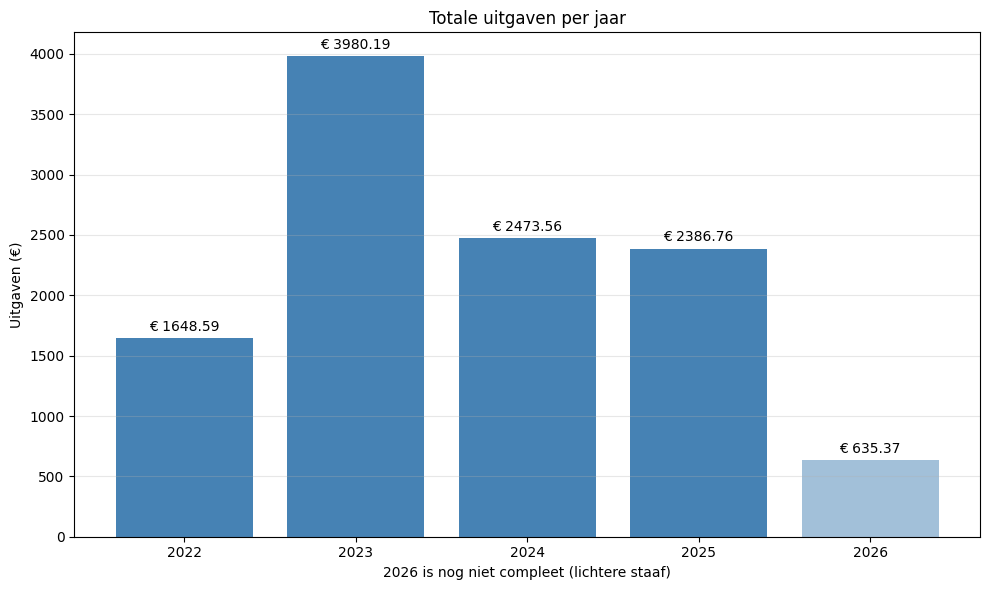

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Kroegrekening.csv", sep=";", skiprows=3,
                 encoding="utf-8-sig", dtype=str)
df.columns = df.columns.str.strip()

def naar_getal(serie):
    return pd.to_numeric(
        serie.fillna("")
             .str.replace("€", "", regex=False)
             .str.replace(".", "", regex=False)
             .str.replace(",", ".", regex=False)
             .str.strip(),
        errors="coerce")

df["Debet"] = naar_getal(df["Debet"])
df["Datum"] = pd.to_datetime(df["Datum"], format="%d-%m-%Y", errors="coerce")

uitgaven = df.dropna(subset=["Datum", "Debet"])
uitgaven = uitgaven[uitgaven["Debet"] > 0].copy()
uitgaven["Jaar"] = uitgaven["Datum"].dt.year

per_jaar = uitgaven.groupby("Jaar")["Debet"].sum()

fig, ax = plt.subplots(figsize=(10, 6))
staven = ax.bar(per_jaar.index.astype(str), per_jaar.values, color="steelblue")
ax.bar_label(staven, fmt="€ %.2f", padding=3)

# Het lopende jaar is nog niet compleet
huidig_jaar = pd.Timestamp.today().year
if huidig_jaar in per_jaar.index:
    staven[list(per_jaar.index).index(huidig_jaar)].set_alpha(0.5)
    ax.set_xlabel(f"{huidig_jaar} is nog niet compleet (lichtere staaf)")

ax.set_title("Totale uitgaven per jaar")
ax.set_ylabel("Uitgaven (€)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

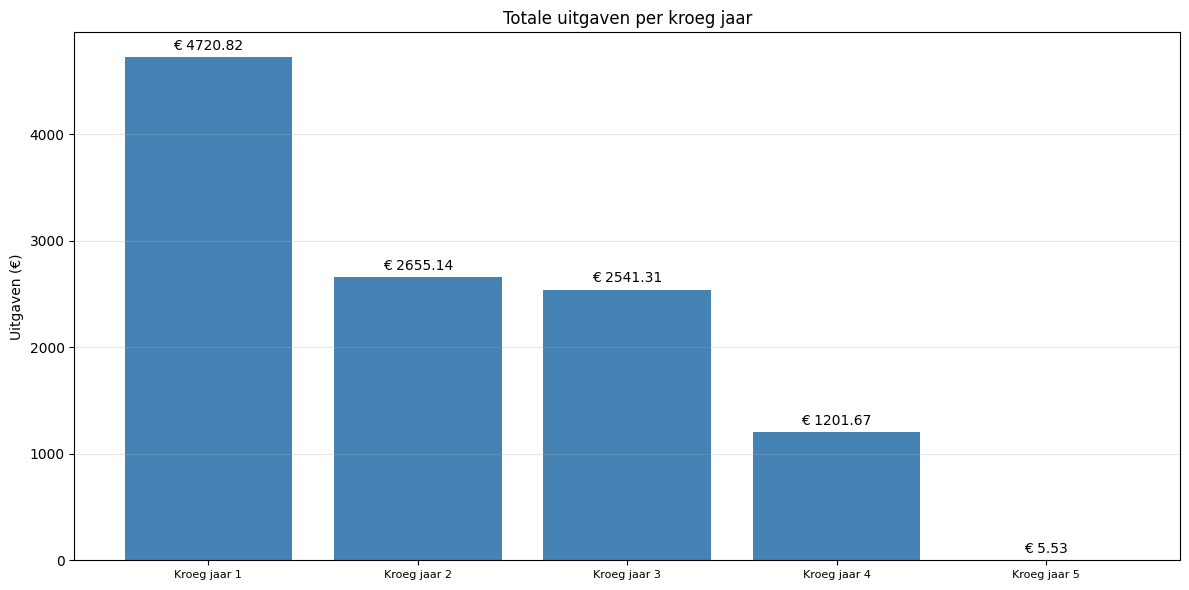

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Kroegrekening.csv", sep=";", skiprows=3,
                 encoding="utf-8-sig", dtype=str)
df.columns = df.columns.str.strip()

def naar_getal(serie):
    return pd.to_numeric(
        serie.fillna("")
             .str.replace("€", "", regex=False)
             .str.replace(".", "", regex=False)
             .str.replace(",", ".", regex=False)
             .str.strip(),
        errors="coerce")

df["Debet"] = naar_getal(df["Debet"])
df["Datum"] = pd.to_datetime(df["Datum"], format="%d-%m-%Y", errors="coerce")

uitgaven = df.dropna(subset=["Datum", "Debet"])
uitgaven = uitgaven[uitgaven["Debet"] > 0].copy()

# Startdatum van jaar 1; elk jaar loopt tot en met de verjaardag van de start
start = pd.Timestamp("2022-08-27")

def jaar_nummer(datum):
    # Jaar k eindigt op start + k jaar (inclusief)
    k = 1
    while datum > start + pd.DateOffset(years=k):
        k += 1
    return k

def periode_tekst(k):
    # Jaar 1 begint op de startdatum, de andere jaren één dag na de vorige einddatum
    begin = start if k == 1 else start + pd.DateOffset(years=k - 1) + pd.Timedelta(days=1)
    eind = start + pd.DateOffset(years=k)
    return f"{begin:%d-%m-%Y} t/m {eind:%d-%m-%Y}"

uitgaven["Jaar"] = uitgaven["Datum"].apply(jaar_nummer)
per_jaar = uitgaven.groupby("Jaar")["Debet"].sum()

labels = [f"Kroeg jaar {k}" for k in per_jaar.index]

fig, ax = plt.subplots(figsize=(12, 6))
staven = ax.bar(labels, per_jaar.values, color="steelblue")
ax.bar_label(staven, fmt="€ %.2f", padding=3)

# Het lopende jaar is nog niet compleet, dus die staaf wordt lichter
huidig = jaar_nummer(pd.Timestamp.today())
if huidig in per_jaar.index:
    staven[list(per_jaar.index).index(huidig)].set_alpha(0.5)

ax.set_title("Totale uitgaven per kroeg jaar")
ax.set_ylabel("Uitgaven (€)")
ax.grid(axis="y", alpha=0.3)
plt.xticks(fontsize=8)
plt.tight_layout()
plt.show()

[Text(0, 3, '€ 4720.82'),
 Text(0, 3, '€ 2655.14'),
 Text(0, 3, '€ 2541.31'),
 Text(0, 3, '€ 1201.67'),
 Text(0, 3, '€ 5.53'),
 Text(0, 3, '€ 11124.47')]

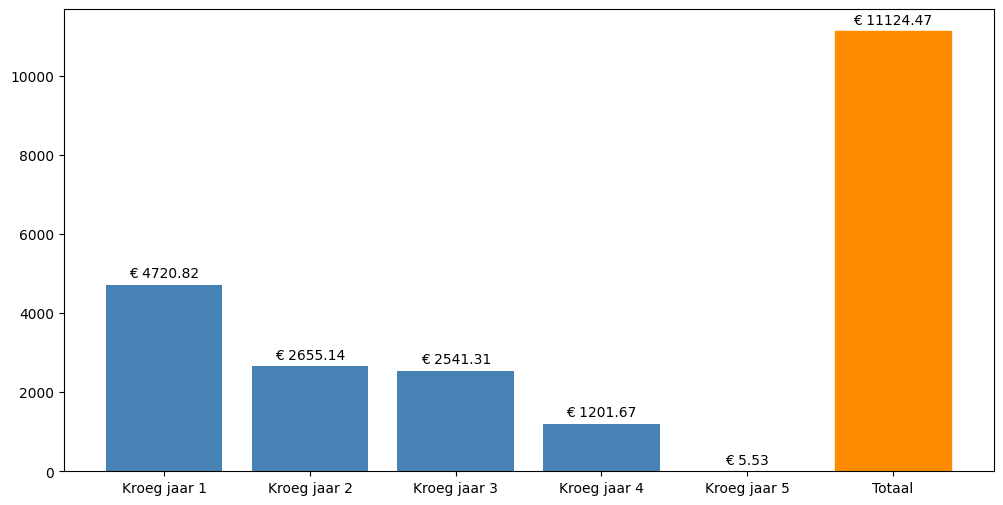

In [33]:
totaal = per_jaar.sum()

labels_met_totaal = labels + ["Totaal"]
waarden = list(per_jaar.values) + [totaal]

fig, ax = plt.subplots(figsize=(12, 6))
staven = ax.bar(labels_met_totaal, waarden, color="steelblue")
staven[-1].set_color("darkorange")  # totaalstaaf in een andere kleur
ax.bar_label(staven, fmt="€ %.2f", padding=3)

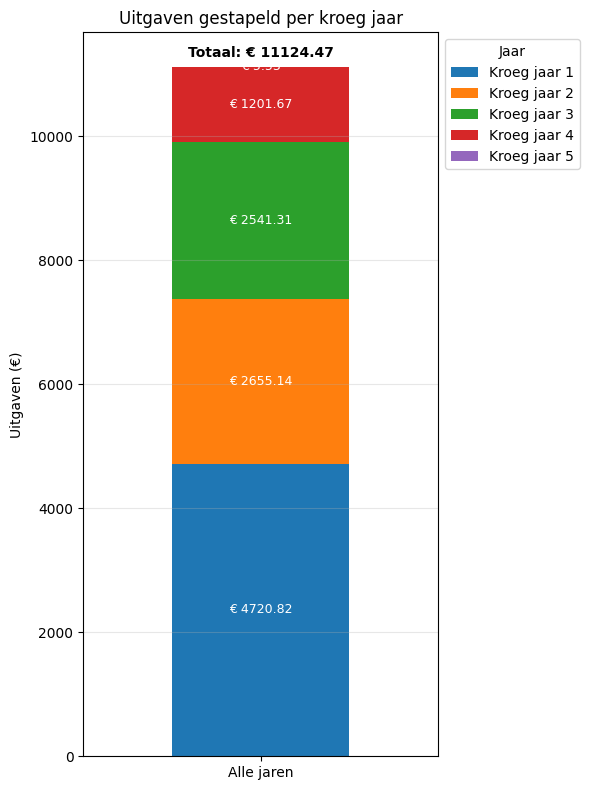

In [34]:
import numpy as np

fig, ax = plt.subplots(figsize=(6, 8))
kleuren = plt.cm.tab10(np.arange(len(per_jaar)))
onder = 0

for (jaar, bedrag), kleur in zip(per_jaar.items(), kleuren):
    ax.bar(0, bedrag, bottom=onder, width=0.5, color=kleur, label=f"Kroeg jaar {jaar}")
    ax.text(0, onder + bedrag / 2, f"€ {bedrag:.2f}", ha="center", va="center",
            color="white", fontsize=9)
    onder += bedrag

ax.text(0, onder * 1.01, f"Totaal: € {onder:.2f}", ha="center", va="bottom",
        fontweight="bold")
ax.set_xticks([0])
ax.set_xticklabels(["Alle jaren"])
ax.set_xlim(-0.5, 0.5)
ax.set_ylabel("Uitgaven (€)")
ax.set_title("Uitgaven gestapeld per kroeg jaar")
ax.legend(title="Jaar", loc="upper left", bbox_to_anchor=(1, 1))
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()